<a href="https://colab.research.google.com/github/SergeiVKalinin/MSE_Fall_2026/blob/main/Module%206/29_SHAP_Image.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SHAP for Image Models — Classroom Tutorial (from official SHAP notebooks)

Original code is MIT-licensed from the SHAP repository(https://shap.readthedocs.io/).

## Contents
1. Setup
2. MNIST — DeepExplainer (PyTorch)
3. VGG16 — Intermediate Layer (PyTorch + GradientExplainer)
4. ResNet50 — PartitionExplainer (PyTorch)
5. ResNet50 — Multi-class (TensorFlow)
6. Wrap-up

## 1) Setup
Installs/validates dependencies for SHAP, PyTorch, Torchvision, TensorFlow, and imaging utilities. Run this first. Colab users: it will auto-install any missing packages.

In [1]:
import sys, subprocess
def pip_install(args):
    if isinstance(args, str): args = args.split()
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q'] + args)
def ensure(pkg, pip_name=None):
    try: __import__(pkg)
    except Exception: pip_install([pip_name or pkg])
ensure('shap'); ensure('numpy'); ensure('matplotlib'); ensure('PIL','Pillow'); ensure('requests')
try:
    import torch, torchvision
except Exception:
    pip_install(['torch','torchvision','--index-url','https://download.pytorch.org/whl/cpu'])
    import torch, torchvision
try:
    import tensorflow as tf
except Exception:
    pip_install(['tensorflow'])
    import tensorflow as tf
import shap, numpy as np, matplotlib.pyplot as plt
from PIL import Image
print('Versions -> shap:', shap.__version__, '| torch:', torch.__version__, '| tf:', tf.__version__)

Versions -> shap: 0.54.1 | torch: 2.14.1+cpu | tf: 2.21.0


## 2) MNIST — DeepExplainer (PyTorch)

**Goal:** Introduce SHAP on a simple CNN. Look for pixels that increase/decrease confidence for the predicted digit.

**Try:** Reduce/increase background samples; observe stability/noise in attributions.

> **Provenance:** adapted from **PyTorch Deep Explainer MNIST example** (SHAP GitHub).

# PyTorch Deep Explainer MNIST example

A simple example showing how to explain an MNIST CNN trained using PyTorch with Deep Explainer.

In [2]:
import numpy as np
import torch
from torch import nn, optim
from torch.nn import functional as F
from torchvision import datasets, transforms

import shap

In [3]:
batch_size = 128
num_epochs = 2
device = torch.device("cpu")


class Net(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv_layers = nn.Sequential(
            nn.Conv2d(1, 10, kernel_size=5),
            nn.MaxPool2d(2),
            nn.ReLU(),
            nn.Conv2d(10, 20, kernel_size=5),
            nn.Dropout(),
            nn.MaxPool2d(2),
            nn.ReLU(),
        )
        self.fc_layers = nn.Sequential(
            nn.Linear(320, 50),
            nn.ReLU(),
            nn.Dropout(),
            nn.Linear(50, 10),
            nn.Softmax(dim=1),
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = x.view(-1, 320)
        x = self.fc_layers(x)
        return x


def train(model, device, train_loader, optimizer, epoch):
    model.train()
    for batch_idx, (data, target) in enumerate(train_loader):
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        output = model(data)
        loss = F.nll_loss(output.log(), target)
        loss.backward()
        optimizer.step()
        if batch_idx % 100 == 0:
            print(
                f"Train Epoch: {epoch} [{batch_idx * len(data)}/{len(train_loader.dataset)}"
                f" ({100.0 * batch_idx / len(train_loader):.0f}%)]"
                f"\tLoss: {loss.item():.6f}"
            )


def test(model, device, test_loader):
    model.eval()
    test_loss = 0
    correct = 0
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = model(data)
            test_loss += F.nll_loss(output.log(), target).item()  # sum up batch loss
            pred = output.max(1, keepdim=True)[1]  # get the index of the max log-probability
            correct += pred.eq(target.view_as(pred)).sum().item()

    test_loss /= len(test_loader.dataset)
    print(
        f"\nTest set: Average loss: {test_loss:.4f},"
        f" Accuracy: {correct}/{len(test_loader.dataset)}"
        f" ({100.0 * correct / len(test_loader.dataset):.0f}%)\n"
    )


train_loader = torch.utils.data.DataLoader(
    datasets.MNIST(
        "mnist_data",
        train=True,
        download=True,
        transform=transforms.Compose([transforms.ToTensor()]),
    ),
    batch_size=batch_size,
    shuffle=True,
)

test_loader = torch.utils.data.DataLoader(
    datasets.MNIST("mnist_data", train=False, transform=transforms.Compose([transforms.ToTensor()])),
    batch_size=batch_size,
    shuffle=True,
)

model = Net().to(device)
optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.5)

for epoch in range(1, num_epochs + 1):
    train(model, device, train_loader, optimizer, epoch)
    test(model, device, test_loader)

100%|██████████| 9.91M/9.91M [00:01<00:00, 6.57MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 154kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.47MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.05MB/s]


Train Epoch: 1 [0/60000 (0%)]	Loss: 2.316068
Train Epoch: 1 [12800/60000 (21%)]	Loss: 2.135545
Train Epoch: 1 [25600/60000 (43%)]	Loss: 1.256757
Train Epoch: 1 [38400/60000 (64%)]	Loss: 0.855946
Train Epoch: 1 [51200/60000 (85%)]	Loss: 0.647939

Test set: Average loss: 0.0044, Accuracy: 9036/10000 (90%)

Train Epoch: 2 [0/60000 (0%)]	Loss: 0.585319
Train Epoch: 2 [12800/60000 (21%)]	Loss: 0.624711
Train Epoch: 2 [25600/60000 (43%)]	Loss: 0.398271
Train Epoch: 2 [38400/60000 (64%)]	Loss: 0.566439
Train Epoch: 2 [51200/60000 (85%)]	Loss: 0.579905

Test set: Average loss: 0.0024, Accuracy: 9363/10000 (94%)



In [4]:
# since shuffle=True, this is a random sample of test data
batch = next(iter(test_loader))
images, _ = batch

background = images[:100]
test_images = images[100:103]

e = shap.DeepExplainer(model, background)
shap_values = e.shap_values(test_images)

In [5]:
shap_numpy = list(np.transpose(shap_values, (4, 0, 2, 3, 1)))
test_numpy = np.swapaxes(np.swapaxes(test_images.numpy(), 1, -1), 1, 2)

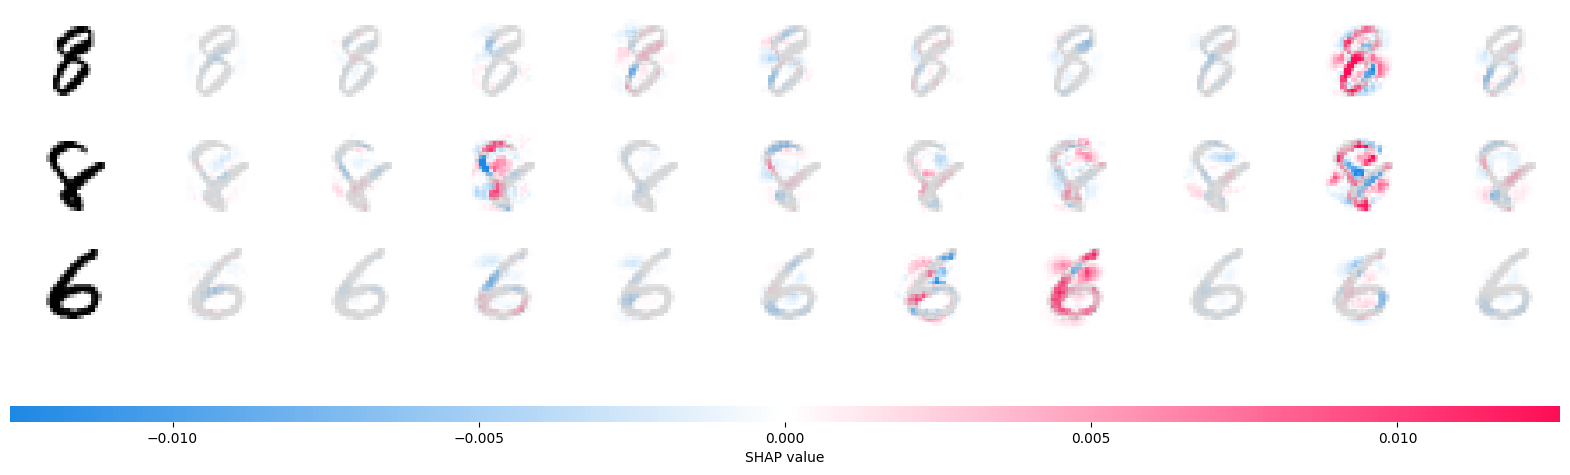

In [6]:
# plot the feature attributions
shap.image_plot(shap_numpy, -test_numpy)

The plot above shows the explanations for each class on four predictions. Note that the explanations are ordered for the classes 0-9 going left to right along the rows.

## 3) VGG16 — Intermediate Layer (PyTorch + GradientExplainer)

**Concept:** Explain **intermediate** features, not just final logits. Change the layer index and compare results.

**Try:** Tune `nsamples` and inspect how attribution variance changes.

> **Provenance:** adapted from **Explain an Intermediate Layer of VGG16 on ImageNet** (SHAP GitHub).

# Explain an Intermediate Layer of VGG16 on ImageNet

Explaining a prediction in terms of the original input image is harder than explaining the predicition in terms of a higher convolutional layer (because the higher convolutional layer is closer to the output). This notebook gives a simple example of how to use GradientExplainer to do explain a model output with respect to the 7th layer of the pretrained VGG16 network.

Note that by default 200 samples are taken to compute the expectation. To run faster you can lower the number of samples per explanation.

553467096/553467096 ━━━━━━━━━━━━━━━━━━━━ 26s 0us/step


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━
┃ Layer (type)                                        ┃ Output Shape                           ┃               Para
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━
│ input_layer (InputLayer)                            │ (None, 224, 224, 3)                    │                   
├─────────────────────────────────────────────────────┼────────────────────────────────────────┼───────────────────
│ block1_conv1 (Conv2D)                               │ (None, 224, 224, 64)                   │                 1,
├─────────────────────────────────────────────────────┼────────────────────────────────────────┼───────────────────
│ block1_conv2 (Conv2D)                               │ (None, 224, 224, 64)                   │                36,
├─────────────────────────────────────────────────────┼────────────────────────────────────────┼───────────────────
│ block1_pool (MaxPooling2D)                          │ (None, 112, 112, 64)                   │                   
├─────────────────────────────────────────────────────┼────────────────────────────────────────┼───────────────────
│ block2_conv1 (Conv2D)                               │ (None, 112, 112, 128)                  │                73,
├─────────────────────────────────────────────────────┼────────────────────────────────────────┼───────────────────
│ block2_conv2 (Conv2D)                               │ (None, 112, 112, 128)                  │               147,
├─────────────────────────────────────────────────────┼────────────────────────────────────────┼───────────────────
│ block2_pool (MaxPooling2D)                          │ (None, 56, 56, 128)                    │                   
├─────────────────────────────────────────────────────┼────────────────────────────────────────┼───────────────────
│ block3_conv1 (Conv2D)                               │ (None, 56, 56, 256)                    │               295,
├─────────────────────────────────────────────────────┼────────────────────────────────────────┼───────────────────
│ block3_conv2 (Conv2D)                               │ (None, 56, 56, 256)                    │               590,
├─────────────────────────────────────────────────────┼────────────────────────────────────────┼───────────────────
│ block3_conv3 (Conv2D)                               │ (None, 56, 56, 256)                    │               590,
├─────────────────────────────────────────────────────┼────────────────────────────────────────┼───────────────────
│ block3_pool (MaxPooling2D)                          │ (None, 28, 28, 256)                    │                   
├─────────────────────────────────────────────────────┼────────────────────────────────────────┼───────────────────
│ block4_conv1 (Conv2D)                               │ (None, 28, 28, 512)                    │             1,180,
├─────────────────────────────────────────────────────┼────────────────────────────────────────┼───────────────────
│ block4_conv2 (Conv2D)                               │ (None, 28, 28, 512)                    │             2,359,
├─────────────────────────────────────────────────────┼────────────────────────────────────────┼───────────────────
│ block4_conv3 (Conv2D)                               │ (None, 28, 28, 512)                    │             2,359,
├─────────────────────────────────────────────────────┼────────────────────────────────────────┼───────────────────
│ block4_pool (MaxPooling2D)                          │ (None, 14, 14, 512)                    │                   
├─────────────────────────────────────────────────────┼────────────────────────────────────────┼───────────────────
│ block5_conv1 (Conv2D)                               │ (None, 14, 14, 512)                    │             2,359,
├─────────────────────────────────────────────────────┼─

 Total params: 138,357,544 (527.79 MB)

 Trainable params: 138,357,544 (527.79 MB)

 Non-trainable params: 0 (0.00 B)

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_23
Received: inputs=['Tensor(shape=(2, 56, 56, 256))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_23
Received: inputs=['Tensor(shape=(50, 56, 56, 256))']
  warnings.warn(msg)


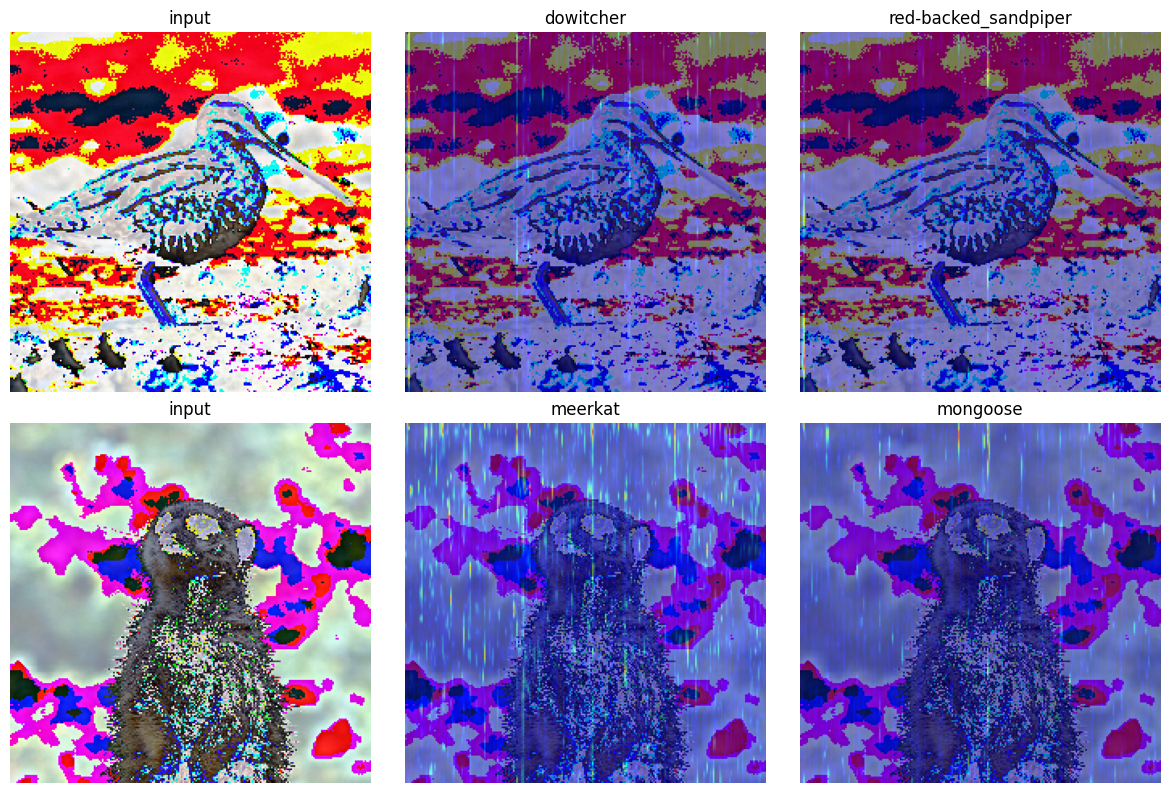

In [7]:
import json, numpy as np, shap, tensorflow as tf
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input

# --- 1) Load model & pick a conv layer index L (explain its OUTPUT)
model = VGG16(weights="imagenet", include_top=True)
L = 7  # e.g., block3_conv1

# Optional: quick summary to see shapes
model.summary(line_length=120)

# --- 2) Sub-models
# image -> layer-L OUTPUT activations
to_layer = tf.keras.Model(inputs=model.input, outputs=model.layers[L].output)

# fresh "tail": layer-L OUTPUT -> final logits
tail_input = tf.keras.Input(shape=to_layer.output.shape[1:])    # e.g., (56,56,256)
x = tail_input
for lyr in model.layers[L+1:]:
    x = lyr(x)
from_layer = tf.keras.Model(inputs=tail_input, outputs=x)

# --- 3) Data & class names
X, _ = shap.datasets.imagenet50()
to_explain = X[[39, 41]].astype(np.float32)

fname = shap.datasets.cache(
    "https://s3.amazonaws.com/deep-learning-models/image-models/imagenet_class_index.json"
)
class_names = json.load(open(fname))

# --- 4) Background & samples at the LAYER (convert to NumPy!)
bg_idx     = np.random.choice(len(X), 50, replace=False)
bg_layer   = to_layer(preprocess_input(X[bg_idx].astype(np.float32))).numpy()  # <-- .numpy()
X_layer    = to_layer(preprocess_input(to_explain)).numpy()                    # <-- .numpy()

# --- 5) SHAP: explain contributions of layer-L OUTPUT to final outputs
e = shap.GradientExplainer((from_layer.input, from_layer.output), bg_layer)
shap_values, indexes = e.shap_values(X_layer, ranked_outputs=2)

# --- 6) Visualize: aggregate channels -> upsample -> overlay
def upsample_to_input(arr2d, H, W):
    return tf.image.resize(arr2d[..., None], (H, W), method="bilinear").numpy().squeeze()

index_names = np.vectorize(lambda k: class_names[str(k)][1])(indexes)
H, W = to_explain.shape[1:3]
N, topk = to_explain.shape[0], len(shap_values)

import matplotlib.pyplot as plt
fig, axes = plt.subplots(N, topk+1, figsize=(4*(topk+1), 4*N))
if N == 1: axes = np.array([axes])

for i in range(N):
    axes[i,0].imshow(to_explain[i].astype(np.uint8)); axes[i,0].set_title("input"); axes[i,0].axis("off")
    for j in range(topk):
        sv   = shap_values[j][i]                    # (h,w,c)
        imp  = np.mean(np.abs(sv), axis=-1)         # (h,w)
        imp  = imp / (imp.max() + 1e-8)
        impU = upsample_to_input(imp, H, W)
        axes[i,j+1].imshow(to_explain[i].astype(np.uint8))
        axes[i,j+1].imshow(impU, cmap="jet", alpha=0.5)
        axes[i,j+1].set_title(index_names[i, j]); axes[i,j+1].axis("off")

plt.tight_layout(); plt.show()


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_62
Received: inputs=['Tensor(shape=(2, 112, 112, 128))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_62
Received: inputs=['Tensor(shape=(50, 112, 112, 128))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_80
Received: inputs=['Tensor(shape=(2, 56, 56, 256))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_80
Received: inputs=['Tensor(shape=(50, 56, 56, 256))']
  warni

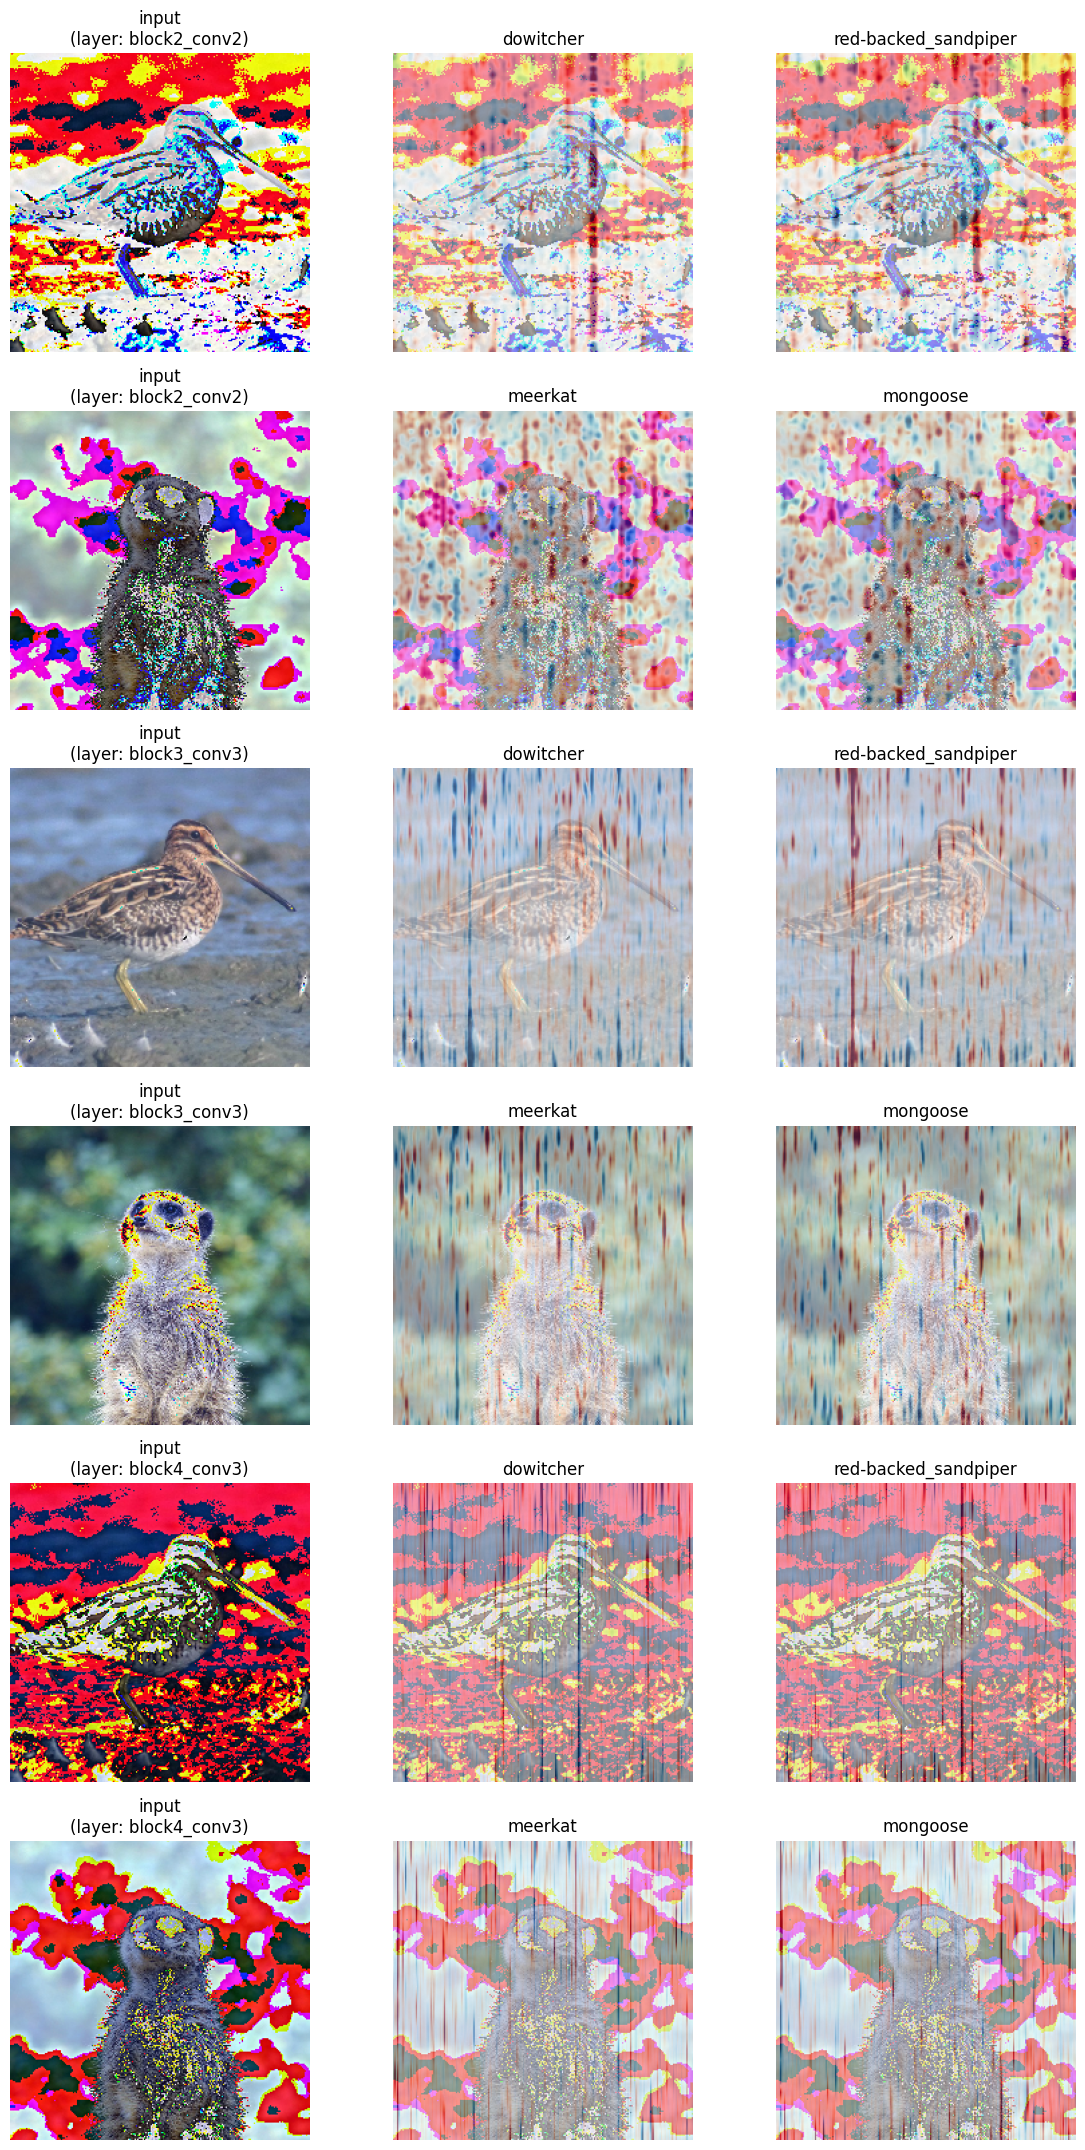

In [8]:
# ==== SHAP across multiple layers (TF2/Keras, VGG16) ====
import json, numpy as np, shap, tensorflow as tf, matplotlib.pyplot as plt
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input
from scipy.ndimage import gaussian_filter

# ----------------- helpers -----------------
def build_tail_from(model, L):
    """Return (to_layer, from_layer) for explaining the OUTPUT of layer L."""
    to_layer = tf.keras.Model(inputs=model.input, outputs=model.layers[L].output)
    tail_input = tf.keras.Input(shape=to_layer.output.shape[1:])
    x = tail_input
    for lyr in model.layers[L+1:]:
        x = lyr(x)
    from_layer = tf.keras.Model(inputs=tail_input, outputs=x)
    return to_layer, from_layer

def signed_heatmap(sv, smooth_sigma=0.8, gamma=0.7, clip_pct=99.0):
    """sv: (h,w,c). Return 2D signed map."""
    h = np.mean(sv, axis=-1)                      # signed channel aggregation
    if smooth_sigma: h = gaussian_filter(h, sigma=smooth_sigma)
    vmax = np.percentile(np.abs(h), clip_pct) + 1e-8
    h = np.clip(h, -vmax, vmax)
    h_norm = h / vmax
    h = np.sign(h_norm) * (np.abs(h_norm)**gamma) * vmax
    return h

def upsample(arr2d, H, W):
    return tf.image.resize(arr2d[..., None], (H, W), method="bilinear").numpy().squeeze()

def class_names_lookup():
    url = "https://s3.amazonaws.com/deep-learning-models/image-models/imagenet_class_index.json"
    fname = shap.datasets.cache(url)
    with open(fname) as f:
        return json.load(f)

# ----------------- load model & data -----------------
model = VGG16(weights="imagenet", include_top=True)
X, _ = shap.datasets.imagenet50()
to_explain = X[[39, 41]].astype(np.float32)      # pick 2 example images; change indices as desired
H, W = to_explain.shape[1:3]
names = class_names_lookup()

# choose layers to compare (indices or names)
# Good progression: low/mid/high conv layers
layers_to_show = [
    model.get_layer("block2_conv2").name,
    model.get_layer("block3_conv3").name,
    model.get_layer("block4_conv3").name,
]
# Convert names to indices
name2idx = {layer.name: i for i, layer in enumerate(model.layers)}
L_list = [name2idx[name] for name in layers_to_show]

# ----------------- run SHAP per layer -----------------
bg_n = 40          # background size (speed vs stability)
topk = 2           # show top-2 classes per image
bg_idx = np.random.choice(len(X), bg_n, replace=False)

fig_rows = to_explain.shape[0]
fig_cols = 1 + topk   # input + topk maps
fig, axes = plt.subplots(
    fig_rows * len(L_list), fig_cols, figsize=(4*fig_cols, 3.6*fig_rows*len(L_list))
)

if axes.ndim == 1: axes = axes[None, :]

row = 0
for L in L_list:
    # submodels
    to_layer, from_layer = build_tail_from(model, L)

    # activations at layer L (NumPy! not tensors)
    bg_layer = to_layer(preprocess_input(X[bg_idx].astype(np.float32))).numpy()
    X_layer  = to_layer(preprocess_input(to_explain)).numpy()

    # explain: layer-L output  -> logits
    expl = shap.GradientExplainer((from_layer.input, from_layer.output), bg_layer)
    sv, idxs = expl.shap_values(X_layer, ranked_outputs=topk)   # sv: list length=topk, each (N,h,w,c)
    idx_names = np.vectorize(lambda k: names[str(k)][1])(idxs)

    # plot per image
    for i in range(to_explain.shape[0]):
        r = row + i
        # input
        axes[r, 0].imshow(to_explain[i].astype(np.uint8))
        axes[r, 0].set_title(f"input\n(layer: {model.layers[L].name})")
        axes[r, 0].axis("off")

        # top-k maps
        for j in range(topk):
            sv_ij = sv[j][i]                       # (h,w,c)
            hmap  = signed_heatmap(sv_ij, smooth_sigma=0.8, gamma=0.7, clip_pct=99.0)
            hmapU = upsample(hmap, H, W)
            vmax = np.max(np.abs(hmapU)) + 1e-8
            axes[r, j+1].imshow(to_explain[i].astype(np.uint8))
            axes[r, j+1].imshow(hmapU, cmap="RdBu_r", vmin=-vmax, vmax=+vmax, alpha=0.55)
            axes[r, j+1].set_title(idx_names[i, j])
            axes[r, j+1].axis("off")

    row += to_explain.shape[0]

plt.tight_layout(); plt.show()


## 4) ResNet50 — PartitionExplainer with Superpixels (PyTorch)

**Idea:** Model-agnostic explanation via superpixels and hierarchical clustering.

**Try:** Change SLIC parameters (`n_segments`, `compactness`, `sigma`) and compare saliency structure.

> **Provenance:** adapted from **Explain ResNet50 using the Partition explainer** (SHAP GitHub).

# Explain ResNet50 using the `Partition` explainer

This notebook demonstrates how to use SHAP to explain image classification models. In this example we are explaining the output of ResNet50 model for classifying images into 1000 ImageNet classes.

In [9]:
import json

from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input

import shap

### Loading Model and Data

In [10]:
# load pre-trained model and data
model = ResNet50(weights="imagenet")
X, y = shap.datasets.imagenet50()

102967424/102967424 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


In [11]:
# getting ImageNet 1000 class names
url = "https://s3.amazonaws.com/deep-learning-models/image-models/imagenet_class_index.json"
with open(shap.datasets.cache(url)) as file:
    class_names = [v[1] for v in json.load(file).values()]
# print("Number of ImageNet classes:", len(class_names))
# print("Class names:", class_names)

### SHAP ResNet50 model explanation for images

Build a partition explainer with:
 - the model (a python function)
 - the masker (a python function)
 - output names (a list of names of the output classes)

## A quick run with a few evaluations

In [12]:
# python function to get model output; replace this function with your own model function.
def f(x):
    tmp = x.copy()
    preprocess_input(tmp)
    return model(tmp)


# define a masker that is used to mask out partitions of the input image.
masker = shap.maskers.Image("inpaint_telea", X[0].shape)

# create an explainer with model and image masker
explainer = shap.Explainer(f, masker, output_names=class_names)

# here we explain two images using 500 evaluations of the underlying model to estimate the SHAP values
shap_values = explainer(X[1:3], max_evals=100, batch_size=50, outputs=shap.Explanation.argsort.flip[:4])

  0%|          | 0/98 [00:00<?, ?it/s]

  0%|          | 0/98 [00:00<?, ?it/s]

PartitionExplainer explainer: 3it [00:16, 16.01s/it]               


#### Explainer options:
1. Above image masker uses a blurring technique called "inpaint_telea". There are alternate masking options available to experiment with such as "inpaint_ns" and "blur(kernel_xsize, kernel_xsize)".
2. Recommended number of evaluations is 300-500 to get explanations with sufficient granularity for the super pixels. More the number of evaluations, more the granularity but also increases run-time.

    Note: `outputs=shap.Explanation.argsort.flip[:4]` has been used in the code above for getting SHAP values because we want to get the top 4 most probable classes for each image i.e. top 4 classes with decreasing probability. Hence, a flip argsort sliced by 4 has been used.

### Visualizing SHAP values output

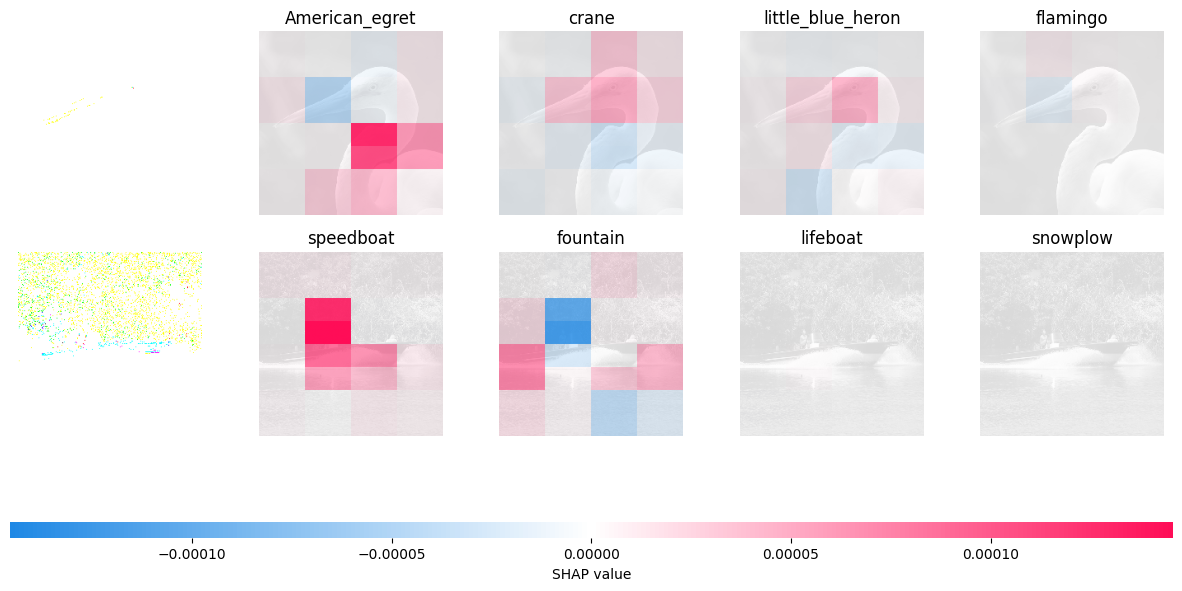

In [13]:
# output with shap values
shap.image_plot(shap_values)

### Interpretation of SHAP output explanation:
1. In the first example, given bird image is classified as an American Egret with next probable classes being a Crane, Heron and Flamingo. It is the "bump" over the bird's neck that causes it to be classified as an American Egret vs a Crane, Heron or a Flamingo. You can see the neck region of the bird appropriately highlighted in red super pixels.    
2. In the second example, it is the shape of the boat which causes it to be classified as a speedboat instead of a fountain, lifeboat or snowplow (appropriately highlighted in red super pixels).

## A longer run with many evaluations

By increasing the `max_evals` parameter we let SHAP execute the original model more times and so get a more finely detailed explaination. We also use the blur kernel here, both to demonstrate it, and because it is much faster than inpainting. Note that this will take a while if you are not using a modern GPU on your system.

In [14]:
# python function to get model output; replace this function with your own model function.
def f(x):
    tmp = x.copy()
    preprocess_input(tmp)
    return model(tmp)


# define a masker that is used to mask out partitions of the input image.
masker_blur = shap.maskers.Image("blur(128,128)", X[0].shape)

# create an explainer with model and image masker
explainer_blur = shap.Explainer(f, masker_blur, output_names=class_names)

# here we explain two images using 500 evaluations of the underlying model to estimate the SHAP values
shap_values_fine = explainer_blur(X[1:3], max_evals=5000, batch_size=50, outputs=shap.Explanation.argsort.flip[:4])

  0%|          | 0/4998 [00:00<?, ?it/s]

PartitionExplainer explainer:  50%|█████     | 1/2 [00:00<?, ?it/s]

  0%|          | 0/4998 [00:00<?, ?it/s]

PartitionExplainer explainer: 3it [06:24, 192.38s/it]


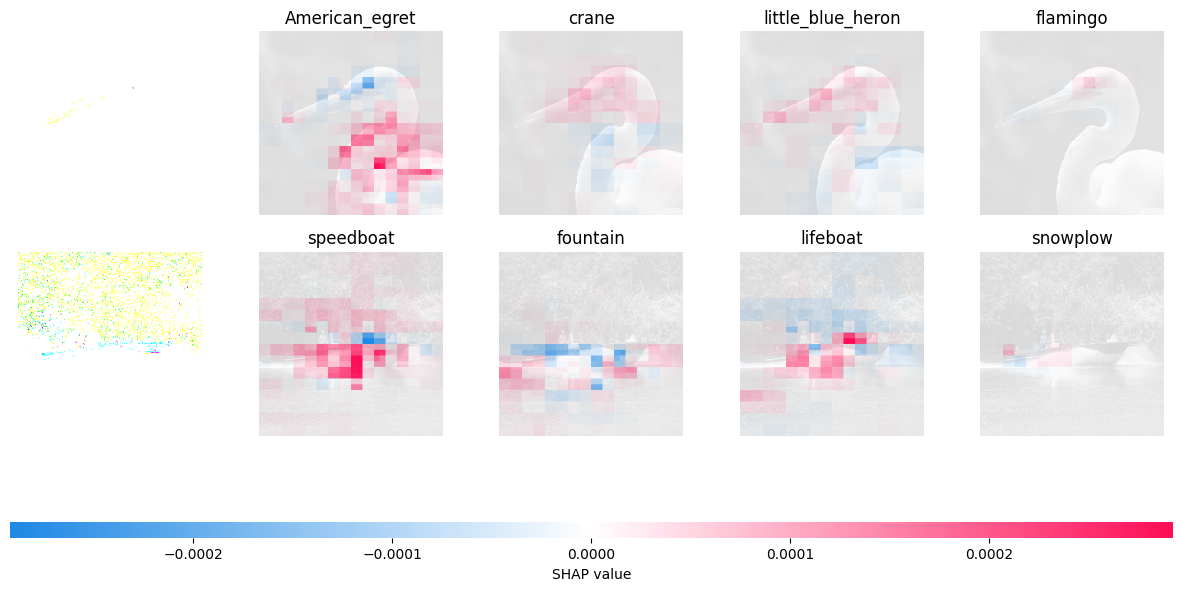

In [15]:
# output with shap values
shap.image_plot(shap_values_fine)

<hr>
Have an idea for more helpful examples? Pull requests that add to this documentation notebook are encouraged!

## 5) ResNet50 — Multi-class attributions (TensorFlow)

**Why this matters:** Many production pipelines use Keras/TF; this mirrors the PyTorch examples in a TF ecosystem.

**Try:** Swap the input images for your dataset and compare attribution patterns.

> **Provenance:** adapted from **Multi-class ResNet50 on ImageNet (TensorFlow)** (SHAP GitHub).

# Multi-class ResNet50 on ImageNet (TensorFlow)

  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer:  50%|█████     | 1/2 [00:00<?, ?it/s]

  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer: 3it [00:55, 27.88s/it]


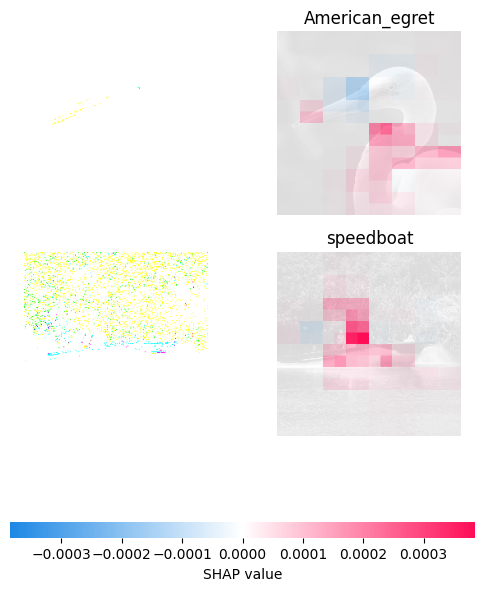

In [16]:
import json

from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input

import shap

# load pre-trained model and choose two images to explain
model = ResNet50(weights="imagenet")


def f(X):
    tmp = X.copy()
    preprocess_input(tmp)
    return model(tmp)


X, y = shap.datasets.imagenet50()

# load the ImageNet class names as a vectorized mapping function from ids to names
url = "https://s3.amazonaws.com/deep-learning-models/image-models/imagenet_class_index.json"
with open(shap.datasets.cache(url)) as file:
    class_names = [v[1] for v in json.load(file).values()]

# define a masker that is used to mask out partitions of the input image, this one uses a blurred background
masker = shap.maskers.Image("inpaint_telea", X[0].shape)

# By default the Partition explainer is used for all  partition explainer
explainer = shap.Explainer(f, masker, output_names=class_names)

# here we use 500 evaluations of the underlying model to estimate the SHAP values
shap_values = explainer(X[1:3], max_evals=500, batch_size=50, outputs=shap.Explanation.argsort.flip[:1])
shap.image_plot(shap_values)

<hr>
Have an idea for more helpful examples? Pull requests that add to this documentation notebook are encouraged!

---
## 6) Wrap-up
- **Deep/GradientExplainer:** Use when you can backprop through the model (white-box). Rich, fast attributions.
- **PartitionExplainer:** Use when the model is black-box. Segmentation choice strongly affects results.
- **Best practice:** Evaluate *stability* (augmentations/seeds), not just single images.

